<a href="https://colab.research.google.com/github/DanielV-13/ADFM----PL_03_dense_vs_convolutional.ipynb/blob/main/ADFM_PL_03_dense_vs_convolutional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis de Datos en Física Moderna
## Pietro Vischia (Universidad de Oviedo and ICTEA), pietro.vischia@cern.ch

The core of this tutorial comes from https://github.com/vischia/data_science_school_igfae2024 (Pietro Vischia (pietro.vischia@cern.ch)).

# Metodología y Diseño Experimental: Redes Densas (MLP) vs. Redes Convolucionales (CNN) en MNIST

**- MULTI-LAYER PERCEPTON  y CONVOLUTIONAL NEURAL NETWORK**

El objetivo de este cuaderno es realizar un análisis comparativo riguroso entre dos paradigmas fundamentales del aprendizaje profundo: las **Redes Neuronales Totalmente Conectadas (Perceptrón Multicapa o MLP)** y las **Redes Neuronales Convolucionales (CNN)**. A través de una exploración sistemática de hiperparámetros, arquitecturas y funciones de pérdida, conectaremos la formulación matemática con el comportamiento empírico durante el entrenamiento sobre el conjunto de datos **MNIST** (imágenes en escala de grises de $28 \times 28$ píxeles distribuidas en 10 clases correspondientes a los dígitos del $0$ al $9$).

---

## 1. Preprocesamiento y Estandarización de Datos
Antes de alimentar cualquier arquitectura neuronal, el espacio de características de entrada $X \in \mathbb{R}^{N \times 1 \times 28 \times 28}$ debe ser acondicionado matemáticamente para estabilizar el flujo de gradientes:

* **Reescalado Lineal (`ToTensor`):** Transforma los valores enteros originales de intensidad de píxel $[0, 255]$ al intervalo continuo $[0.0, 1.0]$. Esto evita saturaciones inmediatas en las activaciones iniciales.
* **Estandarización Z-score (`Normalize`):** Transforma cada píxel $x_{i,j}$ restando la media global ($\mu = 0.1307$) y dividiendo por la desviación estándar ($\sigma = 0.3081$) del conjunto MNIST:
  $$x'_{i,j} = \frac{x_{i,j} - \mu}{\sigma}$$
  *Justificación teórica:* Centrar los datos alrededor de cero con varianza unitaria garantiza que la superficie de la función de pérdida sea más isotrópica (esférica en lugar de elíptica alargada). Esto evita oscilaciones erráticas durante el descenso de gradiente y acelera drásticamente la convergencia de optimizadores adaptativos como **Adam**.

---

## 2. Arquitectura Densa (*Fully Connected* / MLP MULTI LAYER PERCEPTON)
En una red densa, la estructura bidimensional de la imagen se destruye mediante una operación de aplanamiento (*flattening*), proyectando la matriz $28 \times 28$ en un vector unidimensional $\mathbf{x} \in \mathbb{R}^{784}$.

* **Topología y Profundidad:** Definiremos bloques secuenciales compuestos por transformaciones afines $\mathbf{z}^{(l)} = \mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}$ seguidas de no linealidades **ReLU**, $\sigma(z) = \max(0, z)$, para evitar el desvanecimiento del gradiente (*vanishing gradient*) presente en funciones como la sigmoide.
* **Criterio de Dimensionamiento y Explosión de Parámetros:** En una red densa de arquitectura $784 \to 128 \to 64 \to 10$, el número total de parámetros entrenables asciende a:
  $$N_{\text{params}} = (784 \times 128 + 128) + (128 \times 64 + 64) + (64 \times 10 + 10) = 109,386$$
  *Limitación física y geométrica:* El MLP carece de **invarianza traslacional** y no explota la correlación espacial local. Cada píxel es tratado como una variable independiente; si un dígito se desplaza apenas dos píxeles hacia la derecha, la red densa debe reaprender los pesos desde cero para esa nueva posición.

---

## 3. Arquitectura Convolucional (CNN)
Las CNN resuelven la ineficiencia de las redes densas introduciendo dos sesgos inductivos fundamentales inspirados en la corteza visual y en los operadores diferenciales de la física: **conectividad local** y **compartición de pesos (*weight sharing*)**.

* **Operación de Convolución Discreta (`Conv2d`):** Un filtro o *kernel* $\mathbf{K} \in \mathbb{R}^{k \times k}$ se desliza sobre la imagen calculando productos internos locales:
  $$(I * K)(i, j) = \sum_{m=0}^{k-1} \sum_{n=0}^{k-1} I(i + m, j + n) \cdot K(m, n)$$
  *Analogía con Física de Partículas (Señal vs. Fondo):* Cada filtro actúa como un detector especializado de patrones locales (bordes verticales, curvas, trazos diagonales). Las regiones de la imagen que coinciden con la morfología del filtro generan una activación intensa (**Señal**), mientras que el espacio vacío o irrelevante es suprimido a valores cercanos a cero (**Fondo**).
* **Estudio Comparativo de Kernels ($k \times k$):** Evaluaremos cómo el tamaño del campo receptivo afecta la extracción de características:
  * **Kernels pequeños ($3 \times 3$):** Capturan detalles locales muy finos con un costo computacional bajo ($9$ parámetros por canal). Al apilar múltiples capas de $3 \times 3$, se logra un campo receptivo efectivo equivalente a filtros más grandes pero con mayor no linealidad y menor número de parámetros.
  * **Kernels medianos/grandes ($5 \times 5$ o $7 \times 7$):** Abarcan un contexto espacial más amplio en una sola capa ($25$ a $49$ parámetros por canal), pero incrementan el costo cuadrático de operaciones por ventana y tienden a suavizar detalles de alta frecuencia.
* **Control Espacial (`Padding` y `Stride`) y Submuestreo (`MaxPool2d`):** Utilizaremos *padding* para preservar las dimensiones en los bordes de la imagen y capas de `MaxPool2d` ($2 \times 2$, *stride* $2$) para reducir la resolución espacial a la mitad en cada etapa ($28 \times 28 \to 14 \times 14 \to 7 \times 7$), otorgando invarianza local ante pequeñas distorsiones y reduciendo la carga computacional antes del clasificador denso final.

---

## 4. Dinámica de Entrenamiento y Eficiencia Computacional
El rendimiento de una arquitectura no solo se mide por su precisión final, sino por su eficiencia temporal y estabilidad numérica:

* **Rapidez de Entrenamiento y Complejidad Computacional:** Aunque una CNN tiene **significativamente menos parámetros entrenables** que un MLP (a menudo entre $5\times$ y $10\times$ menos), requiere un mayor número de operaciones de punto flotante (**FLOPs**) por pasada hacia adelante (*forward pass*) debido a que cada filtro recorre espacialmente toda la matriz de entrada. Compararemos empíricamente el tiempo de ejecución por época (`wall-clock time`) frente a la velocidad de convergencia por iteración.
* **Esquema de Optimización y Planificación (`Adam` + `ExponentialLR`):** Evaluaremos el impacto del tamaño de lote (*batch size*) en la varianza del gradiente estocástico y utilizaremos decaimiento exponencial de la tasa de aprendizaje ($\eta_t = \eta_0 \cdot \gamma^t$) para realizar ajustes finos en el mínimo de la función de costo durante las últimas épocas.

---

## 5. Funciones de Pérdida y Evaluación de Desempeño
* **Entropía Cruzada Multiclase (`CrossEntropyLoss`):** Combina internamente una activación **Log-Softmax** sobre los *logits* crudos de salida $\mathbf{z} \in \mathbb{R}^{10}$ con la pérdida de verosimilitud logarítmica negativa (*Negative Log-Likelihood*):
  $$\mathcal{L}(\mathbf{z}, y) = -\log\left(\frac{e^{z_y}}{\sum_{j=0}^{9} e^{z_j}}\right) = -z_y + \log\left(\sum_{j=0}^{9} e^{z_j}\right)$$
  *Criterio matemático:* Penaliza logarítmicamente las predicciones seguras pero erróneas, generando gradientes limpios y proporcionales al error ($\frac{\partial \mathcal{L}}{\partial z_i} = p_i - y_i$) sin requerir una capa `Softmax` explícita al final del modelo.
* **Métricas Continuas vs. Discretizadas:**
  * Analizaremos la evolución continua de la **función de pérdida** (capacidad de calibración probabilística y detección temprana de sobreajuste o *overfitting* cuando la pérdida de validación diverge respecto a la de entrenamiento).
  * Contrastaremos esto con métricas discretizadas mediante el operador $\arg\max$: la **Exactitud Global (*Accuracy*)** y la **Matriz de Confusión** ($10 \times 10$), identificando qué pares de dígitos presentan mayor solapamiento morfológico (ej. confundir un `4` con un `9`, o un `3` con un `8`).

In [7]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS DE DEEP LEARNING
# ==========================================

import torch       # Framework central de PyTorch para cálculo tensorial y autograd
import torch
import torch.nn as nn   # Módulo de redes neuronales (capas, funciones de pérdida, contenedores secuenciales)
import torch.optim as optim  # Algoritmos de optimización (Adam, SGD, etc.) para actualización de pesos
import torch.nn.functional as F    # Funciones operacionales sin estado (activaciones, pooling funcional)
from torch.utils.data import DataLoader  # Gestor para cargar lotes de datos (batching) y barajarlos (shuffling)
import torchvision          # Librería auxiliar con datasets estándar (MNIST) y transformaciones de imagen
from tqdm import tqdm     # Utilidad para mostrar barras de progreso interactivas en bucles de entrenamiento


# ==========================================
# 2. LIBRERÍAS DE VISUALIZACIÓN Y CÁLCULO NUMÉRICO
# ==========================================
import matplotlib    # Librería base para la generación de gráficos
%matplotlib inline
# Comando mágico para renderizar las gráficas directamente dentro del entorno de Colab

import matplotlib.pyplot as plt  # Interfaz de Pyplot para trazar curvas de pérdida, precisión y matrices de confusión
import numpy as np       # Librería fundamental para manipulación eficiente de matrices y operaciones numéricas



# ==========================================
# 3. CONFIGURACIÓN DEL HARDWARE DE EJECUCIÓN
# ==========================================
# Detecta automáticamente si hay una GPU NVIDIA disponible (CUDA).
# Si existe, asigna el cálculo a la tarjeta gráfica para acelerar masivamente el entrenamiento;
# de lo contrario, recurre de forma segura al procesador principal (CPU).
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Load the MNIST dataset and inspect it.
This dataset is handily hosted in the package `torchvision`.

You can also apply a series of transformations, e.g. the following if you want to standardize automatically the dataset to the global mean and variance. Suggestion: start by not standardizing.

NOTE: the standardization transform is called `normalize` in the package `torchvision`.

```
transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ]))
```

Another transform it is usually done is to divide values in the image by `255` to have them before 0 and 1.

In [4]:
batch_size = 64 # Or whichever value you may see fit
# You can also explore whether dense and convolutional networks work best with different batch sizes

# Load Data
train_dataset = torchvision.datasets.MNIST(root='dataset/', train=True, transform=torchvision.transforms.ToTensor(),
                                           #target_transform = torchvision.transforms.Compose([
                                           # lambda x:torch.LongTensor([x]), # or just torch.tensor
                                           # lambda x:F.one_hot(x,10)]),
                                            download=True)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = torchvision.datasets.MNIST(root='dataset/', train=False, transform=torchvision.transforms.ToTensor(),
#target_transform = torchvision.transforms.Compose([
#                                 lambda x:torch.LongTensor([x]), # or just torch.tensor
#                                 lambda x:F.one_hot(x,10)]),
                                          download=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 36.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.03MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.11MB/s]


We can inspect the dataset.

Suggestion: inspect the dataset after trying out different transforms.

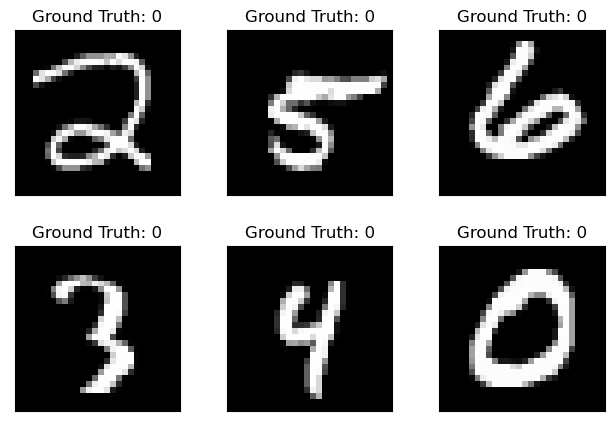

In [ ]:
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)

example_data.shape

import matplotlib.pyplot as plt

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Ground Truth: {}".format(torch.argmax(example_targets[i])))
  plt.xticks([])
  plt.yticks([])


Define a fully connected neural network model


In [ ]:
class DenseNetwork(nn.Module):
    def __init__(self, input_size, num_classes, device=torch.device("cpu")):
        super().__init__()
        self.dense = nn.Sequential(
            # here put layers. Some choices you have seen are:
            #     nn.Dropout(p=0.4),
            #     nn.Linear(input_size, 128),
            #     nn.BatchNorm1d(128),
            #     nn.ReLU(),
            #     nn.sigmoid(),
            #     nn.Softmax(dim=1)
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )
        self.dense.to(device)

    def forward(self, x):
        x = self.dense(x)
        return x


In [ ]:
input_size = 28*28*1 # You have to figure this out
num_classes = 10 # You have to figure this out
learning_rate = 0.001 # You have to figure this out
num_epochs = 3 # You have to figure this out

# Initialize Network
model = DenseNetwork(input_size=input_size, num_classes=num_classes).to(device)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

total_pars, trainable_pars = count_parameters(model)
print("I have ", total_pars, "parameter and ", trainable_pars, " trainable parameters")

print("len", len([i for i in model.parameters()]))
# Loss and Optimizer
loss_fn = torch.nn.CrossEntropyLoss() # You have to figure this out
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

I have  109386 parameter and  109386  trainable parameters
len 6


The transformation `torchvision.transforms.Normalize` does what we call *Standardizatio*, that is it rescales data to have the same mean and variance. Here, the two hardcoded values are the mean and variance of the whole MNIST data set.


In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer, scheduler, cnn, device):
    losses=[] # Track the loss function
    accs= [] # Track accuracies

    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
    for batch, (X, y) in enumerate(dataloader):
    #for batch, (X, y) in tqdm(enumerate(dataloader, 0), unit="batch", total=len(dataloader)):
    #for (X,y) in tqdm(dataloader):
        # Reset gradients (to avoid their accumulation)
        optimizer.zero_grad()
        # Compute prediction and loss
        if not cnn:
            X = X.reshape(X.shape[0], -1)
        pred = model(X)

        #print("Y", y)
        #pred= pred.reshape([pred.shape[0], 1, num_classes])
        #print(torch.argmax(pred, dim=2), torch.argmax(y, dim=2))
        loss = loss_fn(pred,y)
        #print(loss)
        losses.append(loss.detach().cpu())
        acc = (torch.argmax(pred, 1) == y).float().mean()
        accs.append(acc.detach().cpu())
        loss.backward()
        optimizer.step()

    return np.mean(losses), np.mean(accs)

def test_loop(dataloader, model, loss_fn, cnn, device):

    losses=[] # Track the loss function
    accs = [] # Track accuracies
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        #for batch, (X, y) in tqdm(enumerate(dataloader, 0), unit="batch", total=len(dataloader)):
        for (X,y) in tqdm(dataloader):
            if not cnn:
                X = X.reshape(X.shape[0], -1)
            pred = model(X)
            #pred= pred.reshape([pred.shape[0], 1, num_classes])
            loss = loss_fn(pred, y)
            acc = (torch.argmax(pred, 1) == y).float().mean()
            losses.append(loss)
            accs.append(acc.detach().cpu())
            test_loss += loss
            #correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    return np.mean(losses), np.mean(accs)


In [ ]:
train_losses=[]
test_losses=[]
train_accuracies=[]
test_accuracies=[]
for t in range(num_epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss, train_accuracy = train_loop(train_loader, model, loss_fn, optimizer, scheduler, False, device)
    test_loss, test_accuracy = test_loop(test_loader, model, loss_fn, False, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    print("Avg train loss", train_loss, ", Avg test loss", test_loss, "Current learning rate", scheduler.get_last_lr())
print("Done!")

Now let's create a convolutional network

Relevant parameters:

- `in_channels`: number of input channels. For black-and-white images, this is 1. RGB images have 3.
- `num_classes`: how many digits do we want to recognize?

The first `Conv2d` layer has 8 kernels of size 3x3, i.e. splits the image in eight separate channels each with its own convolution operation. Padding ensures the size of the image remains the same.
The second `Conv2d` layer has 16 filters, also with 3x3 kernel.

The `MaxPool2d` layer has a 2x2 kernel and a stride of 2. This does averaging and dimensional reduction, downsampling the image by a factor 2 in each dimension (from 28x28 to 14x14 the first time we apply it, and from 14x14 to 7x7 the second time).

The output of the second `Conv2d` layer will therefore a 16-channel image where each channel is 7x7. We flatten it to a one-dimensional vector per image to feed it to a dense layer that does classification.


In [ ]:
class ConvNetwork(nn.Module):
    def __init__(self, in_channels=1, num_classes=10):
        super(ConvNetwork, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            nn.Flatten(),
            nn.Linear(16*7*7, num_classes)
            # Another activation function here? Or not?
        )
    def forward(self, x):
        x = self.conv(x)
        return x




Now we change the input parameters accordingly (in general they won't be the same as the dense network) and instatiate the convolutional network

In [ ]:
in_channels = 1 # You have to figure this out
num_classes = 10 # You have to figure this out
learning_rate = 0.01 # You have to figure this out
num_epochs = 5 # You have to figure this out

# Initialize Network
model = ConvNetwork(in_channels=in_channels, num_classes=num_classes).to(device)

# Loss and Optimizer
criterion = torch.nn.CrossEntropyLoss() # You have to figure this out
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

Now you can train again. The training and test look will be the same, but you will need to change the names in the loop below to save the training data for the convolutional network


In [ ]:
conv_train_losses=[]
conv_test_losses=[]
conv_train_accuracies=[]
conv_test_accuracies=[]
for t in range(num_epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    conv_train_loss, conv_train_accuracy = train_loop(train_loader, model, loss_fn, optimizer, scheduler, True, device)
    conv_test_loss, conv_test_accuracy = test_loop(test_loader, model, loss_fn, True, device)
    conv_train_losses.append(conv_train_loss)
    conv_train_accuracies.append(conv_train_accuracy)
    conv_test_losses.append(conv_test_loss)
    conv_test_accuracies.append(conv_test_accuracy)
    print("Avg train loss", conv_train_loss, ", Avg test loss", conv_test_loss, "Current learning rate", scheduler.get_last_lr())
print("Done!")

Now you can for instance plot the losses for both networks (train and test data sets), build the confusion matrix for the two networks, check how many trainable parameters (remember `torchinfo.summary(model)`...) are needed for each network type to give you a certain performance, and other useful stuff for the report